# Share a hyperparameter

Two priors can share one hyperparameter.
In this guide, the means of two groups share one prior scale.
The model then has three hyperparameters instead of four.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

## Imports

In [2]:
from typing import Any

import tensorflow_probability as tfp

import elicito as el

tfd = tfp.distributions

## The generative model

The outcomes $y_a$ and $y_b$ are normal, with means $\mu_a$ and $\mu_b$
and standard deviation 1.

In [3]:
class Model:
    """Normal outcomes of two groups"""

    def __call__(self, prior_samples: Any) -> dict[str, Any]:
        """
        Simulate the outcomes of both groups

        Parameters
        ----------
        prior_samples
            samples from the prior distributions

        Returns
        -------
        :
            dictionary with the model outputs
        """
        ya = tfd.Normal(loc=prior_samples[:, :, 0], scale=1.0).sample()
        yb = tfd.Normal(loc=prior_samples[:, :, 1], scale=1.0).sample()
        return dict(ya=ya, yb=yb)

## The shared hyperparameter

Give the hyperparameter the same name in both priors.
Set `shared=True` in both.

In [4]:
scale = el.hyper("s", lower=0, shared=True)
parameters = [
    el.parameter("mu_a", tfd.Normal, dict(loc=el.hyper("m_a"), scale=scale)),
    el.parameter("mu_b", tfd.Normal, dict(loc=el.hyper("m_b"), scale=scale)),
]
targets = [
    el.quantiles("ya", probs=(0.25, 0.50, 0.75)),
    el.quantiles("yb", probs=(0.25, 0.50, 0.75)),
]

## Training

The answers come from an oracle.
Its priors are $\mu_a \sim \text{Normal}(5, 2)$ and $\mu_b \sim \text{Normal}(10, 2)$.

In [5]:
expert = el.expert.simulator(
    ground_truth={"mu_a": tfd.Normal(5.0, 2.0), "mu_b": tfd.Normal(10.0, 2.0)}
)
eliobj = el.Elicit(
    Model(), targets, parameters, seeds=(2025,), epochs=400, verbose=False
)
fit = eliobj.fit(expert)
fit

Method: parametric_prior (400 epochs)
Shown: replication [0] (best)

Hyperparameters:
      estimate
m_a       4.94
m_b       9.97
s         1.93

Priors:
           mean         sd        q05        q95
mu_a       4.94       1.93       1.76       8.11
mu_b       9.97       1.93        6.8       13.2

Fit to expert:
          expert   elicited      error
ya[0]       3.46       3.51     0.0502
ya[1]       4.96       4.96   -0.00589
ya[2]       6.48       6.41    -0.0688
yb[0]       8.45        8.5      0.052
yb[1]       9.95       9.96     0.0143
yb[2]       11.5       11.4    -0.0816

Loss by target:
    technique       loss
ya  quantiles      0.108
yb  quantiles      0.106

Final loss:
   final_loss
0       0.214

The summary lists three hyperparameters.
The learned values must be near $m_a = 5$, $m_b = 10$ and $s = 2$.

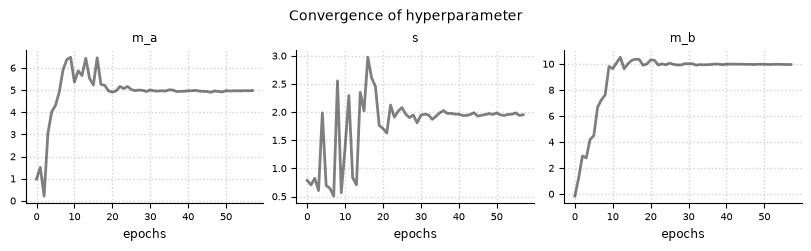

In [6]:
fit.plot.hyperparameter(cols=3, figsize=(8, 2.4))